In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

En la obra de una variante de carretera, la actividad **D** es la excavación de un desmonte y la actividad **E** el terraplén de un relleno. El cuadro de prelaciones, las duraciones (semanas) y el movimiento de tierras de cada actividad (`tierras_m3`: positivo, m³ que se excavan; negativo, m³ que hacen falta) se adjuntan. El estudio geotécnico confirma que el material del desmonte es apto para el relleno y no está contaminado.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, tierras_m3
    ('A'     , '---'      , 2       , 0         ),
    ('B'     , '---'      , 1       , 0         ),
    ('C'     , 'A,B'      , 3       , 0         ),
    ('D'     , 'C'        , 3       , 34000     ),
    ('E'     , 'C'        , 5       , -34000    ),
    ('F'     , 'D,E'      , 4       , 0         ),
    ('G'     , 'F'        , 6       , 0         ),
    ('H'     , 'G'        , 2       , 0         ),
], columns=['activity', 'predecessor', 'duration', 'tierras_m3']).set_index('activity')
datos_enunciado

,predecessor,duration,tierras_m3
activity,,,
A,---,2,0
B,---,1,0
C,"A,B",3,0
D,C,3,34000
E,C,5,-34000
F,"D,E",4,0
G,F,6,0
H,G,2,0


Costes (€ por m³): llevar tierras al vertedero de inertes, 4.0 de canon (impuesto incluido) más el transporte a 25 km; traer material de préstamo de la cantera, 9.0 más el transporte a 30 km; mover las tierras dentro de la obra, 1.2; si hay que acopiarlas y volver a cargarlas, 2.5 más. Transporte por carretera: 0.12 €/t·km y 0.1 kg CO₂/t·km; densidad 1.8 t/m³. Penalidad por retraso: 12 k€ por semana.

> **De: Jefe de obra**
> Las tierras de D al vertedero y el terraplén de E con préstamo de cantera, como está en el plan: E empieza antes de que D termine y no voy a tener la obra llena de montones. El gestor se lo lleva, la cantera lo trae y cada actividad va a su ritmo. Son tierras: no es un residuo de verdad.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S13 — Materiales excavados: reutilizar en la obra es prevención.** Los suelos no contaminados y otros materiales naturales excavados que se reutilizan en su estado natural en la misma obra no son residuo; los que salen de la obra sí lo son (salvo valorización autorizada) y entran en la jerarquía por el escalón que les corresponda. Reutilizar en la obra es prevención, el primer escalón; si la reutilización es posible sin acopio o sin retraso lo decide la secuencia del cronograma (las fechas y holguras de la excavación y del relleno), que tiene respuesta determinada. *(cf. Ley 7/2022, arts. 3.2.b) y 8; Orden APM/1007/2017 (valorización de materiales naturales excavados en otra obra); PMBOK 8 §3.7 (figura 3-7).)*
- **S8 — Jerarquía de residuos y separación en origen.** El orden es prevención, preparación para la reutilización, reciclado, otra valorización y, en último lugar, eliminación. Los residuos de construcción y demolición no peligrosos se clasifican, preferentemente en la obra, en al menos seis fracciones (madera, minerales, metales, vidrio, plástico y yeso) y la demolición es selectiva, previo estudio de las cantidades de cada fracción. Mezclarlo todo en un contenedor que va a vertedero es elegir el último escalón e incumplir la obligación de clasificar. *(cf. Ley 7/2022 de residuos y suelos contaminados, arts. 8 y 30; RD 105/2008 (estudio y plan de gestión de RCD).)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **Norma o dato de referencia — quedan fuera de la ley de residuos los suelos excavados no contaminados y otros materiales naturales excavados en actividades de construcción cuando se tenga la certeza de que se utilizarán con fines de construcción en su estado natural en el lugar u obra donde fueron extraídos; los que salen de la obra son residuo (tierras a vertedero de inertes) salvo que se valoricen conforme a la orden ministerial de valorización de materiales naturales excavados** *(Ley 7/2022, art. 3.2.b); Orden APM/1007/2017.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Haga el balance de tierras (m³ excavados, necesarios, reutilizables, sobrante y déficit) y calcule el coste y las emisiones del transporte de la propuesta (todo al vertedero y todo de préstamo) y de la alternativa de reutilizar en la obra lo que se pueda.  "
pregunta_2 = "2. (A) Con el calendario, determine si E puede empezar cuando termina D sin retrasar el proyecto (fin más temprano de D frente a inicio más temprano y más tardío de E), si hace falta acopio o retraso, y el coste total de cada opción con la penalidad. ¿Cuánto vale el «no tener montones»?  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿son residuo las tierras que se reutilizan en la obra? ¿Y las que van al vertedero? ¿En qué escalón de la jerarquía queda cada opción? ¿Puede reutilizarse sin acopio ni retraso con el calendario del plan?  "
pregunta_4 = "4. (C) ¿Qué propone al jefe de obra y qué comunica a la dirección facultativa? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Haga el balance de tierras (m³ excavados, necesarios, reutilizables, sobrante y déficit) y calcule el coste y las emisiones del transporte de la propuesta (todo al vertedero y todo de préstamo) y de la alternativa de reutilizar en la obra lo que se pueda.  

2. (A) Con el calendario, determine si E puede empezar cuando termina D sin retrasar el proyecto (fin más temprano de D frente a inicio más temprano y más tardío de E), si hace falta acopio o retraso, y el coste total de cada opción con la penalidad. ¿Cuánto vale el «no tener montones»?  

3. (B) Según el criterio y la norma de referencia, ¿son residuo las tierras que se reutilizan en la obra? ¿Y las que van al vertedero? ¿En qué escalón de la jerarquía queda cada opción? ¿Puede reutilizarse sin acopio ni retraso con el calendario del plan?  

4. (C) ¿Qué propone al jefe de obra y qué comunica a la dirección facultativa? Aplique la rúbrica.  

# Resolución

In [6]:
desmonte, terraplen, penalidad = 'D', 'E', 12
coste_vertedero, coste_prestamo, coste_interno, coste_acopio = 4.0, 9.0, 1.2, 2.5
km_vertedero, km_prestamo, coste_camion, factor_camion, densidad = 25, 30, 0.12, 0.1, 1.8
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

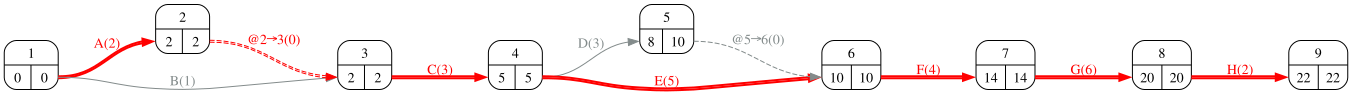

In [8]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Haga el balance de tierras (m³ excavados, necesarios, reutilizables, sobrante y déficit) y calcule el coste y las emisiones del transporte de la propuesta (todo al vertedero y todo de préstamo) y de la alternativa de reutilizar en la obra lo que se pueda.  

In [10]:
#| tbl-cap: "Balance de tierras y coste del transporte de cada opción"
#| label: tbl-balance
V_exc = float(datos_proyecto.loc[desmonte, 'tierras_m3']); V_nec = float(-datos_proyecto.loc[terraplen, 'tierras_m3'])
reutilizable = min(V_exc, V_nec); sobrante = V_exc - reutilizable; deficit = V_nec - reutilizable
c_vert = coste_vertedero + densidad * km_vertedero * coste_camion
c_prest = coste_prestamo + densidad * km_prestamo * coste_camion
e_vert = densidad * km_vertedero * factor_camion / 1000; e_prest = densidad * km_prestamo * factor_camion / 1000   # t CO₂ por m³
balance = pd.Series({'excavado (m³)': V_exc, 'necesario (m³)': V_nec, 'reutilizable (m³)': reutilizable, 'sobrante a vertedero (m³)': sobrante, 'déficit de préstamo (m³)': deficit})
display(balance.to_frame('m³').T)
opciones = pd.DataFrame({'propuesta: vertedero + préstamo': [V_exc * c_vert / 1000, V_nec * c_prest / 1000, 0.0, (V_exc * e_vert + V_nec * e_prest)],
                         'reutilizar en obra': [sobrante * c_vert / 1000, deficit * c_prest / 1000, reutilizable * coste_interno / 1000, (sobrante * e_vert + deficit * e_prest)]},
                        index=['vertedero (k€)', 'préstamo (k€)', 'transporte interno (k€)', 'emisiones del transporte (t CO₂)'])
opciones.loc['coste de tierras (k€)'] = opciones.iloc[:3].sum()
display(opciones.round(1))
Markdown(f'''Vertedero: {c_vert:.2f} €/m³ puesto allí; préstamo: {c_prest:.2f} €/m³ puesto en obra. La propuesta mueve {V_exc + V_nec:,.0f} m³ por carretera ({opciones.iloc[4, 0]:.1f} k€, {opciones.iloc[3, 0]:.1f} t); reutilizar deja en {sobrante + deficit:,.0f} m³ lo que sale o entra ({opciones.iloc[4, 1]:.1f} k€, {opciones.iloc[3, 1]:.1f} t).''')

,excavado (m³),necesario (m³),reutilizable (m³),sobrante a vertedero (m³),déficit de préstamo (m³)
m³,34000.0,34000.0,34000.0,0.0,0.0


,propuesta: vertedero + préstamo,reutilizar en obra
vertedero (k€),319.6,0.0
préstamo (k€),526.3,0.0
transporte interno (k€),0.0,40.8
emisiones del transporte (t CO₂),336.6,0.0
coste de tierras (k€),845.9,40.8


Vertedero: 9.40 €/m³ puesto allí; préstamo: 15.48 €/m³ puesto en obra. La propuesta mueve 68,000 m³ por carretera (845.9 k€, 336.6 t); reutilizar deja en 0 m³ lo que sale o entra (40.8 k€, 0.0 t).

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. (A) Con el calendario, determine si E puede empezar cuando termina D sin retrasar el proyecto (fin más temprano de D frente a inicio más temprano y más tardío de E), si hace falta acopio o retraso, y el coste total de cada opción con la penalidad. ¿Cuánto vale el «no tener montones»?  

In [12]:
#| tbl-cap: "Fechas del desmonte y del terraplén"
#| label: tbl-fechas
fechas = calendario.loc[[desmonte, terraplen], ['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio', 'H_total']]
display(fechas)
ef_x = int(calendario.loc[desmonte, 'fin_mas_temprano']); es_y = int(calendario.loc[terraplen, 'inicio_mas_temprano']); ls_y = int(calendario.loc[terraplen, 'inicio_mas_tardio'])
desplazamiento = max(0, ef_x - es_y)
retraso = max(0, ef_x - ls_y)
necesita_acopio = es_y > ef_x
coste_reutilizar = opciones.loc['coste de tierras (k€)', 'reutilizar en obra'] + (reutilizable * coste_acopio / 1000 if necesita_acopio else 0) + retraso * penalidad
coste_propuesta = opciones.loc['coste de tierras (k€)', 'propuesta: vertedero + préstamo']
comparacion = pd.DataFrame({'propuesta': [coste_propuesta, 0, 0, coste_propuesta], 'reutilizar': [opciones.loc['coste de tierras (k€)', 'reutilizar en obra'], (reutilizable * coste_acopio / 1000 if necesita_acopio else 0), retraso * penalidad, coste_reutilizar]},
                           index=['tierras (k€)', 'acopio (k€)', 'penalidad por retraso (k€)', 'total (k€)'])
display(comparacion.round(1))
Markdown(f'''{desmonte} termina, como pronto, en la semana {ef_x}; {terraplen} puede empezar entre la semana {es_y} y la {ls_y}. ''' + (f'''Empezar {terraplen} al terminar {desmonte} exige desplazarlo {desplazamiento} semana(s), ''' + ('que caben en su holgura: **sin retraso ni acopio**.' if retraso == 0 else f'''{retraso} más de las que caben en su holgura: el proyecto se retrasa **{retraso}** semana(s) ({retraso * penalidad} k€).''') if not necesita_acopio else f'''{desmonte} termina antes de que {terraplen} pueda empezar: hacen falta {es_y - ef_x} semana(s) de acopio ({reutilizable * coste_acopio / 1000:.1f} k€), sin retraso.''') + f''' Reutilizar cuesta **{coste_reutilizar:.1f} k€** frente a **{coste_propuesta:.1f}** de la propuesta: los «montones» valen {coste_propuesta - coste_reutilizar:.1f} k€.''')

,inicio_mas_temprano,fin_mas_temprano,inicio_mas_tardio,fin_mas_tardio,H_total
activity,,,,,
D,5,8,7,10,2
E,5,10,5,10,0


,propuesta,reutilizar
tierras (k€),845.9,40.8
acopio (k€),0.0,0.0
penalidad por retraso (k€),0.0,36.0
total (k€),845.9,76.8


D termina, como pronto, en la semana 8; E puede empezar entre la semana 5 y la 5. Empezar E al terminar D exige desplazarlo 3 semana(s), 3 más de las que caben en su holgura: el proyecto se retrasa **3** semana(s) (36 k€). Reutilizar cuesta **76.8 k€** frente a **845.9** de la propuesta: los «montones» valen 769.1 k€.

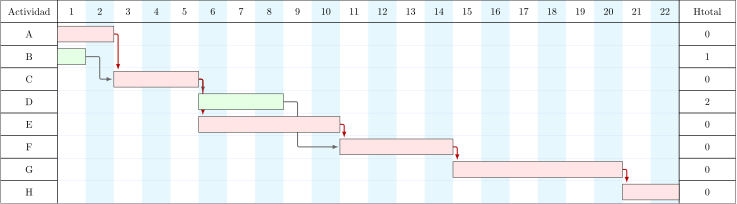

In [13]:
#| fig-cap: "Gantt con holguras: la ventana en la que puede moverse el terraplén"
#| label: fig-gantt
_g, _dibujo = proyecto.copy().gantt(datos_proyecto, 'duration', holguras=True, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_dibujo)

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿son residuo las tierras que se reutilizan en la obra? ¿Y las que van al vertedero? ¿En qué escalón de la jerarquía queda cada opción? ¿Puede reutilizarse sin acopio ni retraso con el calendario del plan?  

**Norma y S13.** Las tierras que se reutilizan en su estado natural en la misma obra **no son residuo** (Ley 7/2022, art. 3.2.b); las que salen al vertedero **sí lo son** (y pagan canon e impuesto), y las 0 m³ sobrantes lo serán en cualquier caso salvo que se valoricen en otra obra conforme a la Orden APM/1007/2017. «No es un residuo de verdad» es cierto sólo para lo que se queda en la obra. **S8.** Reutilizar es **prevención**, el primer escalón; llevar a vertedero tierras aptas es **eliminación**, el último, y traer de cantera lo que ya se tenía consume un recurso natural además. **S1.** La propuesta ni compensa ni minimiza: traslada el impacto al vertedero, a la cantera y a la carretera. Y la pregunta del calendario tiene respuesta única: D termina en la semana 8 y E puede empezar como tarde en la 5; desplazar el terraplén supera su holgura en 3 semana(s): se reutiliza **con 3 semana(s) de retraso** (36 k€), que sigue siendo más barato que la propuesta. Lo que decide no es la opinión sobre los montones, sino las fechas.

In [15]:
preguntas_test = [
    ('Los suelos no contaminados excavados que se reutilizan en su estado natural en la misma obra…', ['no son residuo (Ley 7/2022, art. 3.2.b)', 'son residuo inerte', 'son residuo no peligroso', 'son residuo salvo que lo autorice el gestor'],
     'S13: exclusión del ámbito de la ley de residuos.'),
    ('Reutilizar las tierras de la excavación en los rellenos de la misma obra es, en la jerarquía de residuos…', ['prevención', 'reciclado', 'otra valorización', 'eliminación'],
     'S8: no se genera el residuo.'),
    ('El relleno puede empezar justo al terminar la excavación sin retrasar el proyecto si…', ['el fin más temprano de la excavación no supera el inicio más tardío del relleno', 'el relleno es crítico', 'la excavación tiene holgura', 'los volúmenes coinciden'],
     'Lección 05: desplazar dentro de la holgura total no mueve el fin.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — tierras sobrantes')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — tierras sobrantes

::Sostenibilidad 20 — tierras sobrantes P1::Los suelos no contaminados excavados que se reutilizan en su estado natural en la misma obra… {=no son residuo (Ley 7/2022, art. 3.2.b) ~son residuo inerte ~son residuo no peligroso ~son residuo salvo que lo autorice el gestor ####S13: exclusión del ámbito de la ley de residuos.}

::Sostenibilidad 20 — tierras sobrantes P2::Reutilizar las tierras de la excavación en los rellenos de la misma obra es, en la jerarquía de residuos… {~eliminación =prevención ~otra valorización ~reciclado ####S8: no se genera el residuo.}

::Sostenibilidad 20 — tierras sobrantes P3::El relleno puede empezar justo al terminar la excavación sin retrasar el proyecto si… {~los volúmenes coinciden =el fin más temprano de la excavación no supera el inicio más tardío del relleno ~el relleno es crítico ~la excavación tiene holgura ####Lección 05: desplazar dentro de la holgura total no mueve el fin.}



## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al jefe de obra y qué comunica a la dirección facultativa? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al jefe de obra: la tabla del apartado 2 y el plan de movimiento de tierras con fechas: D a su ritmo, E desplazado hasta la semana 8 aceptando 3 semana(s) de retraso, o D acelerado para evitarlas (lección 10); el sobrante (0 m³) a vertedero o, mejor, ofrecido a otra obra con la orden de valorización. A la dirección facultativa: el estudio de gestión de residuos actualizado con el balance de tierras. Prueba del ciclo de vida: ¿quién paga los camiones de ida al vertedero y los de vuelta de la cantera, y qué queda en cada sitio?